# Book Recommender System (Medallion Data Lake)
Name: Sankaramaddi Yamini  
Roll No: LCS2023031

In [1]:
import html
import io
import os
import re
import zipfile
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from scipy.sparse import csr_matrix, load_npz, save_npz
from sklearn.neighbors import NearestNeighbors

pd.set_option("display.max_colwidth", 60)

## Step 1: Set Up the Data Lake and Build the Bronze Layer

In [2]:
for folder in ("bronze", "silver", "gold"):
    os.makedirs(folder, exist_ok=True)

url = "https://cdn.freecodecamp.org/project-data/books/book-crossings.zip"
resp = requests.get(url, timeout=120)
resp.raise_for_status()

with zipfile.ZipFile(io.BytesIO(resp.content)) as zf:
    users_raw = pd.read_csv(zf.open("BX-Users.csv"), sep=";", encoding="latin-1")
    books_raw = pd.read_csv(zf.open("BX-Books.csv"), sep=";", encoding="latin-1", escapechar="\\", low_memory=False)
    ratings_raw = pd.read_csv(zf.open("BX-Book-Ratings.csv"), sep=";", encoding="latin-1")

ts = datetime.now(timezone.utc).isoformat()
for df in (users_raw, books_raw, ratings_raw):
    df["ingestion_timestamp"] = ts

users_raw.to_parquet("bronze/users.parquet", index=False)
books_raw.to_parquet("bronze/books.parquet", index=False)
ratings_raw.to_parquet("bronze/ratings.parquet", index=False)

print("Saved bronze parquet files:", sorted(os.listdir("bronze")))

Saved bronze parquet files: ['books.parquet', 'ratings.parquet', 'users.parquet']


## Step 2: Explore the Bronze Data (EDA)

In [3]:
b_users = pd.read_parquet("bronze/users.parquet")
b_books = pd.read_parquet("bronze/books.parquet")
b_ratings = pd.read_parquet("bronze/ratings.parquet")

for name, df in [("Users", b_users), ("Books", b_books), ("Ratings", b_ratings)]:
    print(f"{name}: shape={df.shape}")
    display(pd.DataFrame({"dtype": df.dtypes.astype(str), "nulls": df.isna().sum()}))

Users: shape=(278858, 4)


,dtype,nulls
User-ID,int64,0
Location,str,0
Age,float64,110762
ingestion_timestamp,str,0


Books: shape=(271379, 9)


,dtype,nulls
ISBN,str,0
Book-Title,str,0
Book-Author,str,2
Year-Of-Publication,int64,0
Publisher,str,2
Image-URL-S,str,0
Image-URL-M,str,0
Image-URL-L,str,0
ingestion_timestamp,str,0


Ratings: shape=(1149780, 4)


,dtype,nulls
User-ID,int64,0
ISBN,str,0
Book-Rating,int64,0
ingestion_timestamp,str,0


Users has 278,858 rows with 110,762 missing ages, Books has 271,379 rows with 2 missing authors/publishers and unused image URLs, and Ratings has 1,149,780 rows with no nulls; in Silver I will impute ages, drop the image-URL columns, fill missing text with `"Unknown"`, and remove duplicates.

Zero ratings: 716,109 out of 1,149,780 (62.28%)


,count
Book-Rating,
0,716109
1,1770
2,2759
3,5996
4,8904
5,50974
6,36924
7,76457
8,103736


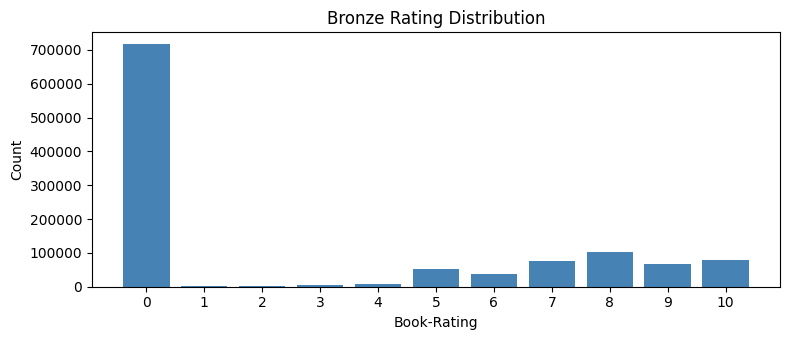

In [4]:
rating_dist = b_ratings["Book-Rating"].value_counts().sort_index()
zeros = int(rating_dist.get(0, 0))
print(f"Zero ratings: {zeros:,} out of {len(b_ratings):,} ({zeros / len(b_ratings) * 100:.2f}%)")
display(rating_dist.to_frame("count"))

plt.figure(figsize=(8, 3.5))
plt.bar(rating_dist.index.astype(str), rating_dist.values, color="steelblue")
plt.title("Bronze Rating Distribution")
plt.xlabel("Book-Rating")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

Over 62% of ratings (716,109 rows) are 0, which represent implicit interactions rather than real scores, so in Silver I will drop all 0s and keep only ratings from 1 to 10.

Age -> min=0.0, max=244.0, <5=882, >100=366, valid median=32.0
Year -> min=0, max=2050, ==0=4619, >2026=11


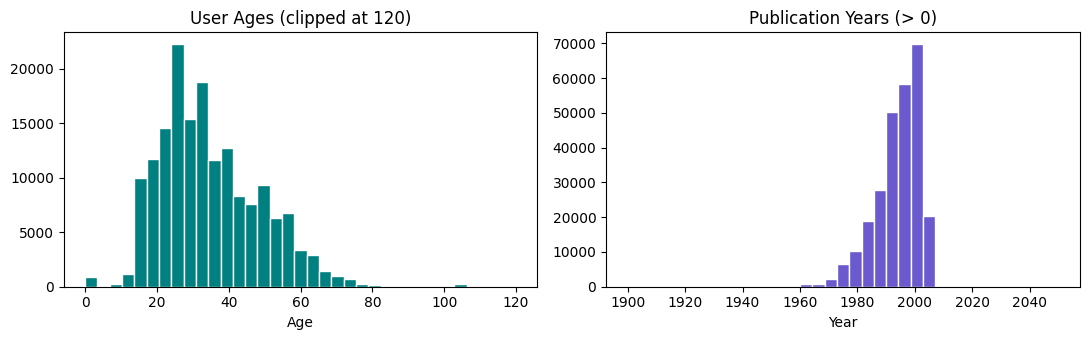

In [5]:
ages = b_users["Age"]
years = pd.to_numeric(b_books["Year-Of-Publication"], errors="coerce")
curr_year = datetime.now().year

print(f"Age -> min={ages.min()}, max={ages.max()}, <5={(ages < 5).sum()}, >100={(ages > 100).sum()}, valid median={ages[ages.between(5, 100)].median()}")
print(f"Year -> min={years.min()}, max={years.max()}, ==0={(years == 0).sum()}, >{curr_year}={(years > curr_year).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(ages.dropna().clip(0, 120), bins=35, color="teal", edgecolor="white")
ax[0].set_title("User Ages (clipped at 120)")
ax[0].set_xlabel("Age")
ax[1].hist(years[years > 0].clip(1900, 2055), bins=35, color="slateblue", edgecolor="white")
ax[1].set_title("Publication Years (> 0)")
ax[1].set_xlabel("Year")
plt.tight_layout()
plt.show()

User ages include impossible values from 0 to 244 (882 below 5 and 366 above 100) and publication years contain 4,619 zeros and 11 future years up to 2050, so in Silver I will set out-of-range ages to null and fill with the median (32.0) and set 0 or future years to null.

,ratings_per_user,ratings_per_book
0.25,1.0,1.0
0.50,1.0,1.0
0.75,4.0,2.0
0.90,12.0,6.0
0.95,29.0,10.0


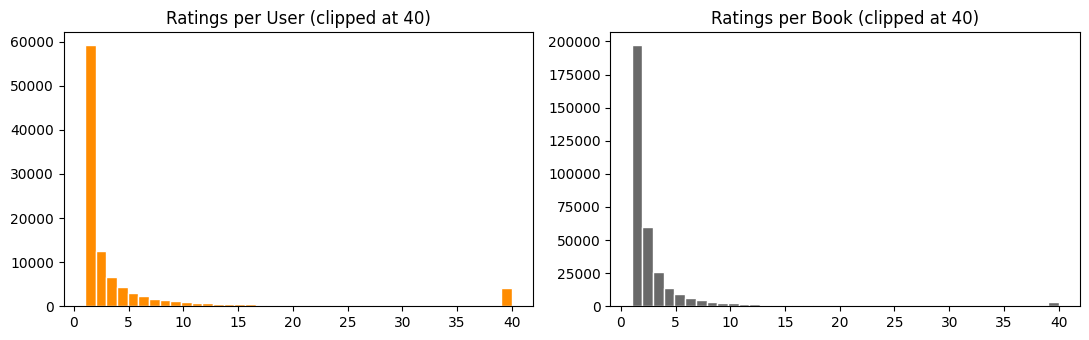

In [6]:
per_user = b_ratings.groupby("User-ID").size()
per_book = b_ratings.groupby("ISBN").size()

display(pd.DataFrame({
    "ratings_per_user": per_user.quantile([0.25, 0.5, 0.75, 0.9, 0.95]),
    "ratings_per_book": per_book.quantile([0.25, 0.5, 0.75, 0.9, 0.95]),
}))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(per_user.clip(upper=40), bins=40, color="darkorange", edgecolor="white")
ax[0].set_title("Ratings per User (clipped at 40)")
ax[1].hist(per_book.clip(upper=40), bins=40, color="dimgray", edgecolor="white")
ax[1].set_title("Ratings per Book (clipped at 40)")
plt.tight_layout()
plt.show()

Half of all users and books only have 1 rating (90% of books have 6 or fewer), so in Silver I will filter out users and books below a minimum rating threshold so collaborative similarity has enough overlap.

In [7]:
n_u = b_users["User-ID"].nunique()
n_b = b_books["ISBN"].nunique()
possible = n_u * n_b
density = len(b_ratings) / possible * 100
print(f"Possible user-book pairs: {possible:,}")
print(f"Actual ratings: {len(b_ratings):,}")
print(f"Populated: {density:.6f}% | Sparsity: {100 - density:.6f}%")

Possible user-book pairs: 75,676,205,182
Actual ratings: 1,149,780
Populated: 0.001519% | Sparsity: 99.998481%


Only 0.001519% of possible user-book pairs are filled (99.998481% sparse), so in Silver I will trim low-activity users/books and orphaned ratings, then store the Gold matrix in sparse format.

## Step 3: Clean the Data and Build the Silver Layer

**Chosen rating threshold: `8`** — From the EDA quantiles, 75% of users have 4 or fewer ratings and 90% of books have 6 or fewer. Requiring at least 8 explicit ratings for both users and books (applied iteratively so every remaining user and book meets the cutoff) removes the sparse long tail while keeping a broader catalog than a cutoff of 10.

In [8]:
users = b_users.drop(columns=["ingestion_timestamp"]).copy()
books = b_books.drop(columns=["ingestion_timestamp"]).copy()
ratings = b_ratings.drop(columns=["ingestion_timestamp"]).copy()

books["ISBN"] = books["ISBN"].astype(str).str.strip().str.upper()
ratings["ISBN"] = ratings["ISBN"].astype(str).str.strip().str.upper()

users = users.drop_duplicates().drop_duplicates(subset=["User-ID"]).copy()
books = books.drop_duplicates().drop_duplicates(subset=["ISBN"]).copy()
ratings = ratings.drop_duplicates().drop_duplicates(subset=["User-ID", "ISBN"]).copy()

ratings = ratings[ratings["Book-Rating"].between(1, 10)].copy()

users.loc[(users["Age"] < 5) | (users["Age"] > 100), "Age"] = np.nan
users["Age"] = users["Age"].fillna(users["Age"].median())

def parse_location(loc):
    if pd.isna(loc):
        return "Unknown", "Unknown", "Unknown"
    parts = [
        re.sub(r"\s+", " ", p).strip().title()
        for p in str(loc).split(",")
        if p.strip() and p.strip().lower() not in {"n/a", "na", "none", "null", "-"}
    ]
    if len(parts) >= 3:
        return ", ".join(parts[:-2]), parts[-2], parts[-1]
    if len(parts) == 2:
        return parts[0], "Unknown", parts[1]
    if len(parts) == 1:
        return parts[0], "Unknown", "Unknown"
    return "Unknown", "Unknown", "Unknown"

users["city"], users["state"], users["country"] = zip(*users["Location"].map(parse_location))
users = users.drop(columns=["Location"])

curr_year = datetime.now().year
books["Year-Of-Publication"] = pd.to_numeric(books["Year-Of-Publication"], errors="coerce")
books.loc[(books["Year-Of-Publication"] <= 0) | (books["Year-Of-Publication"] > curr_year), "Year-Of-Publication"] = np.nan

books = books.drop(columns=["Image-URL-S", "Image-URL-M", "Image-URL-L"])
for col in ("Book-Title", "Book-Author", "Publisher"):
    books[col] = (
        books[col]
        .fillna("Unknown")
        .astype(str)
        .map(html.unescape)
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
        .str.title()
    )

ratings = ratings[ratings["User-ID"].isin(users["User-ID"]) & ratings["ISBN"].isin(books["ISBN"])].copy()

MIN_RATINGS = 8
while True:
    before = len(ratings)
    u_cnt = ratings["User-ID"].value_counts()
    b_cnt = ratings["ISBN"].value_counts()
    ratings = ratings[
        ratings["User-ID"].isin(u_cnt[u_cnt >= MIN_RATINGS].index)
        & ratings["ISBN"].isin(b_cnt[b_cnt >= MIN_RATINGS].index)
    ]
    if len(ratings) == before:
        break

users = users[users["User-ID"].isin(ratings["User-ID"])].reset_index(drop=True)
books = books[books["ISBN"].isin(ratings["ISBN"])].reset_index(drop=True)
ratings = ratings.reset_index(drop=True)

users.to_parquet("silver/users.parquet", index=False)
books.to_parquet("silver/books.parquet", index=False)
ratings.to_parquet("silver/ratings.parquet", index=False)

print(f"Silver shapes -> users: {users.shape}, books: {books.shape}, ratings: {ratings.shape}")
print(f"Silver density: {len(ratings) / (len(users) * len(books)) * 100:.4f}%")

Silver shapes -> users: (2934, 5), books: (3481, 5), ratings: (62546, 3)
Silver density: 0.6124%


## Step 4: Build the Gold Layer

In [9]:
s_users = pd.read_parquet("silver/users.parquet")
s_books = pd.read_parquet("silver/books.parquet")
s_ratings = pd.read_parquet("silver/ratings.parquet")

user_ids = np.sort(s_users["User-ID"].unique())
book_isbns = np.sort(s_books["ISBN"].unique())
u_map = {uid: i for i, uid in enumerate(user_ids)}
b_map = {isbn: i for i, isbn in enumerate(book_isbns)}

mat = csr_matrix(
    (s_ratings["Book-Rating"].astype(np.float32).values, (s_ratings["User-ID"].map(u_map).values, s_ratings["ISBN"].map(b_map).values)),
    shape=(len(user_ids), len(book_isbns)),
)
save_npz("gold/user_book_matrix.npz", mat)

book_lookup = s_books.set_index("ISBN").loc[book_isbns].reset_index()[["ISBN", "Book-Title", "Book-Author"]]
book_lookup.insert(0, "book_idx", np.arange(len(book_isbns)))
book_lookup.to_parquet("gold/book_lookup.parquet", index=False)

user_agg = (
    s_ratings.groupby("User-ID")["Book-Rating"]
    .agg(avg_rating="mean", num_ratings="count")
    .reindex(user_ids)
    .reset_index()
)
user_agg.insert(0, "user_idx", np.arange(len(user_ids)))
user_agg["avg_rating"] = user_agg["avg_rating"].round(3)
user_agg.to_parquet("gold/user_aggregates.parquet", index=False)

book_agg = (
    s_ratings.groupby("ISBN")["Book-Rating"]
    .agg(avg_rating="mean", num_ratings="count")
    .reindex(book_isbns)
    .reset_index()
)
book_agg.insert(0, "book_idx", np.arange(len(book_isbns)))
book_agg["avg_rating"] = book_agg["avg_rating"].round(3)
book_agg.to_parquet("gold/book_aggregates.parquet", index=False)

print(f"Gold matrix: {mat.shape}, stored ratings: {mat.nnz:,}")
display(book_lookup.head(5))

Gold matrix: (2934, 3481), stored ratings: 62,546

,book_idx,ISBN,Book-Title,Book-Author
0,0,000649840X,Angelas Ashes,Frank Mccourt
1,1,0007154615,Unless : A Novel,Carol Shields
2,2,0020198906,Joshua,Joseph F Girzone
3,3,0020199600,Great Gatsby (Reissue),F. Scott Fitzgerald
4,4,0020427859,"Over Sea, Under Stone",Susan Cooper


## Step 5: Build the Recommender (Item-Based Collaborative Filtering)

In [10]:
user_book_mat = load_npz("gold/user_book_matrix.npz")
books_gold = pd.read_parquet("gold/book_lookup.parquet").merge(
    pd.read_parquet("gold/book_aggregates.parquet")[["book_idx", "avg_rating", "num_ratings"]],
    on="book_idx",
)
users_gold = pd.read_parquet("gold/user_aggregates.parquet")
uid_to_row = dict(zip(users_gold["User-ID"], users_gold["user_idx"]))

book_user_mat = user_book_mat.T.tocsr()

nn = NearestNeighbors(metric="cosine", algorithm="brute")
nn.fit(book_user_mat)

def _base_title(title):
    t = str(title)
    while re.search(r"\([^()]*\)", t):
        t = re.sub(r"\s*\([^()]*\)", "", t)
    t = re.sub(r"\s*:\s*a novel.*$", "", t, flags=re.IGNORECASE)
    return re.sub(r"\s+", " ", t).strip().lower()

def similar_books(title, n=10):
    q = title.strip().lower()
    exact = books_gold[books_gold["Book-Title"].str.lower() == q]
    hits = exact if not exact.empty else books_gold[books_gold["Book-Title"].str.lower().str.contains(q, regex=False)]
    if hits.empty:
        raise ValueError(f"Book not found: {title}")

    target = hits.sort_values("num_ratings", ascending=False).iloc[0]
    t_idx = int(target["book_idx"])
    dists, idxs = nn.kneighbors(book_user_mat[t_idx], n_neighbors=min(len(books_gold), n + 20))

    seen = {_base_title(target["Book-Title"])}
    out = []
    for d, i in zip(dists[0], idxs[0]):
        if i == t_idx:
            continue
        row = books_gold.iloc[i]
        key = _base_title(row["Book-Title"])
        if key in seen:
            continue
        seen.add(key)
        out.append({
            "ISBN": row["ISBN"],
            "Title": row["Book-Title"],
            "Author": row["Book-Author"],
            "Similarity": round(float(1 - d), 4),
        })
        if len(out) == n:
            break
    return pd.DataFrame(out)

def _user_history(user_id):
    row_vec = user_book_mat[uid_to_row[user_id]]
    hist = books_gold.iloc[row_vec.indices][["book_idx", "ISBN", "Book-Title", "Book-Author"]].copy()
    hist["User-Rating"] = row_vec.data
    return hist.sort_values("User-Rating", ascending=False).reset_index(drop=True)

def recommend(user_id, n=10):
    if user_id not in uid_to_row:
        raise ValueError(f"User {user_id} not in Gold layer")
    hist = _user_history(user_id)
    read_idxs = set(hist["book_idx"])
    seen_titles = {_base_title(t) for t in hist["Book-Title"]}

    liked = hist[hist["User-Rating"] >= 8]
    if len(liked) < 3:
        liked = hist[hist["User-Rating"] >= hist["User-Rating"].mean()]

    scores = {}
    for _, item in liked.iterrows():
        dists, idxs = nn.kneighbors(book_user_mat[int(item["book_idx"])], n_neighbors=26)
        for d, nb_idx in zip(dists[0], idxs[0]):
            nb_idx = int(nb_idx)
            if nb_idx in read_idxs:
                continue
            sim = float(1 - d)
            if sim > 0:
                scores[nb_idx] = scores.get(nb_idx, 0.0) + sim * float(item["User-Rating"])

    recs = []
    for b_idx, score in sorted(scores.items(), key=lambda x: x[1], reverse=True):
        row = books_gold.iloc[b_idx]
        key = _base_title(row["Book-Title"])
        if key in seen_titles:
            continue
        seen_titles.add(key)
        recs.append({
            "Title": row["Book-Title"],
            "Author": row["Book-Author"],
            "Score": round(score, 3),
        })
        if len(recs) == n:
            break
    return pd.DataFrame(recs)

print("Similar to 'The Da Vinci Code':")
display(similar_books("The Da Vinci Code", n=10))

Similar to 'The Da Vinci Code':


,ISBN,Title,Author,Similarity
0,0671027360,Angels & Demons,Dan Brown,0.2275
1,0374199698,Middlesex: A Novel,Jeffrey Eugenides,0.1578
2,0446531316,Street Dreams,Faye Kellerman,0.1528
3,0316666343,The Lovely Bones: A Novel,Alice Sebold,0.1517
4,0316155306,The Narrows: A Novel,Michael Connelly,0.1492
5,0316154059,City Of Bones,Michael Connelly,0.1448
6,0553802488,The Face,Dean Koontz,0.1421
7,0316780812,Sea Glass: A Novel,Anita Shreve,0.1396
8,0142001740,The Secret Life Of Bees,Sue Monk Kidd,0.1381
9,0525947299,No Second Chance,Harlan Coben,0.1381


## Step 6: Demo and Sanity Check

In [11]:
for uid in [254, 8066, 13582]:
    hist = _user_history(uid)
    liked = (
        hist[hist["User-Rating"] >= 8]
        .assign(_k=lambda d: d["Book-Title"].map(_base_title))
        .drop_duplicates("_k")[["Book-Title", "User-Rating"]]
        .head(10)
        .reset_index(drop=True)
        .rename(columns={"Book-Title": "Highly Rated Book", "User-Rating": "Rating"})
    )
    recs = recommend(uid, n=10).reset_index(drop=True).rename(columns={"Title": "Recommended Book"})

    print(f"User {uid} (total rated: {len(hist)})")
    display(pd.concat([liked, recs], axis=1))

User 254 (total rated: 22)


,Highly Rated Book,Rating,Recommended Book,Author,Score
0,American Gods,10.0,Harry Potter And The Order Of The Phoenix (Book 5),J. K. Rowling,18.886
1,Smoke And Mirrors: Short Fictions And Illusions,9.0,"The Return Of The King (The Lord Of The Rings, Part 3)",J. R. R. Tolkien,10.730
2,The Secret Life Of Bees,9.0,"The Two Towers (The Lord Of The Rings, Part 2)",J. R. R. Tolkien,7.740
3,Harry Potter And The Chamber Of Secrets (Book 2),9.0,Stardust,Neil Gaiman,6.861
4,The Bonesetter'S Daughter,9.0,"The Amber Spyglass (His Dark Materials, Book 3)",Philip Pullman,6.604
5,The Hobbit: Or There And Back Again,9.0,"The Subtle Knife (His Dark Materials, Book 2)",Philip Pullman,5.276
6,Harry Potter And The Sorcerer'S Stone (Book 1),9.0,The Catcher In The Rye,J.D. Salinger,4.875
7,Harry Potter And The Goblet Of Fire (Book 4),9.0,A Brief History Of Time : The Updated And Expanded Tenth...,Stephen Hawking,4.675
8,Harry Potter And The Prisoner Of Azkaban (Book 3),9.0,Dragondrums (Harper Hall Trilogy),Anne Mccaffrey,4.573
9,1984,9.0,Prodigal Summer,Barbara Kingsolver,4.439


User 8066 (total rated: 22)


,Highly Rated Book,Rating,Recommended Book,Author,Score
0,The Secret Life Of Bees,10.0,Blue Shoe,Anne Lamott,4.989
1,Random Acts Of Kindness,10.0,Le Divorce (William Abrahams Book),Diane Johnson,3.756
2,The Hours : A Novel,9.0,The Lake Of Dead Languages (Ballantine Reader'S Circle),Carol Goodman,3.355
3,Life Of Pi,9.0,The Shrinking Of Treehorn,Florence Parry Heide,2.958
4,The Divine Secrets Of The Ya-Ya Sisterhood: A Novel,9.0,Name Dropping : What If Two Very Different Women Had The...,Jane Heller,2.922
5,Chocolat,8.0,Far Side Gallery 3 Paperback,Gary Larson,2.915
6,Good In Bed,8.0,"Galileo'S Daughter: A Historical Memoir Of Science, Fait...",Dava Sobel,2.827
7,Back When We Were Grownups : A Novel (Ballantine Reader'...,8.0,A Son Of The Circus,John Irving,2.680
8,Schindler'S List,8.0,The No. 1 Ladies' Detective Agency,Alexander Mccall Smith,2.628
9,Sister Of My Heart,8.0,"Roll Of Thunder, Hear My Cry",Mildred D. Taylor,2.512


User 13582 (total rated: 22)


,Highly Rated Book,Rating,Recommended Book,Author,Score
0,The Mists Of Avalon,10.0,The Tale Of The Body Thief (Vampire Chronicles (Paperback)),Anne Rice,8.967
1,Wild Swans: Three Daughters Of China,10.0,"Memnoch The Devil (Vampire Chronicles, No 5)",Anne Rice,5.344
2,Misery,9.0,Feast Of All Saints,Anne Rice,5.255
3,Romeo And Juliet,9.0,"Test Of The Twins (Dragonlance Legends, Vol. 3)",Margaret Weis,5.064
4,Hannibal,9.0,Vittorio The Vampire: New Tales Of The Vampires,Anne Rice,5.022
5,The Witching Hour (Lives Of The Mayfair Witches),8.0,The Queen Of The Damned (Vampire Chronicles (Paperback)),Anne Rice,4.468
6,The Cradle Will Fall,8.0,Tropic Of Cancer,Henry Miller,4.277
7,Taltos: Lives Of The Mayfair Witches,8.0,Merrick (Vampire/Witches Chronicles),Anne Rice,4.241
8,Servant Of The Bones,8.0,Interview With The Vampire,Anne Rice,4.183
9,Lasher: Lives Of The Mayfair Witches (Lives Of The Mayfa...,8.0,Violin,Anne Rice,4.001
